In [1120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [1121]:
from pathlib import Path

DATA_PATH = Path("../Dataset/telco_customer_churn.csv")

print("Dataset path:", DATA_PATH.resolve())
print("File exists:", DATA_PATH.exists())

Dataset path: C:\Users\hp\OneDrive\Desktop\Customer_Churn_Prediction_Project\Dataset\telco_customer_churn.csv
File exists: True


In [1122]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,1,Female,0,No,No,49,Yes,No,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Bank transfer (automatic),65.12,3185.16,No
1,2,Male,1,Yes,No,11,Yes,No,Fiber optic,Yes,...,No,No,Yes,No,One year,No,Mailed check,84.56,894.51,No
2,3,Male,0,Yes,Yes,53,Yes,Yes,Fiber optic,Yes,...,No,Yes,No,Yes,Month-to-month,No,Electronic check,90.66,4863.12,No
3,4,Male,0,No,No,26,Yes,Yes,DSL,Yes,...,Yes,No,Yes,Yes,One year,No,Electronic check,65.00,1697.23,No
4,5,Female,0,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Electronic check,18.25,392.47,No


In [1123]:
# Basic Dataset Information

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 21)

First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,1,Female,0,No,No,49,Yes,No,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Bank transfer (automatic),65.12,3185.16,No
1,2,Male,1,Yes,No,11,Yes,No,Fiber optic,Yes,...,No,No,Yes,No,One year,No,Mailed check,84.56,894.51,No
2,3,Male,0,Yes,Yes,53,Yes,Yes,Fiber optic,Yes,...,No,Yes,No,Yes,Month-to-month,No,Electronic check,90.66,4863.12,No
3,4,Male,0,No,No,26,Yes,Yes,DSL,Yes,...,Yes,No,Yes,Yes,One year,No,Electronic check,65.00,1697.23,No
4,5,Female,0,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Electronic check,18.25,392.47,No



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   int64  
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [1124]:
# Check Missing Values

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
display(missing_values[missing_values > 0])

Missing Values in Each Column:


TotalCharges    25
dtype: int64

In [1125]:
# Convert TotalCharges to Numeric

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("TotalCharges converted to numeric.")
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

TotalCharges converted to numeric.
Missing TotalCharges: 25


In [1126]:
# Remove Missing Values

print("Rows before removing missing values:", len(df))

df = df.dropna()

print("Rows after removing missing values:", len(df))
print("Remaining missing values:", df.isnull().sum().sum())

Rows before removing missing values: 7043
Rows after removing missing values: 7018
Remaining missing values: 0


In [1127]:
# Check Duplicate Rows

duplicates = df.duplicated().sum()

print("Duplicate Rows:", duplicates)

Duplicate Rows: 0


In [1128]:
# Remove Duplicate Rows

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (7018, 21)


In [1129]:
# Remove Customer ID

df = df.drop("customerID", axis=1)

print("customerID removed.")
print("Current Shape:", df.shape)
print("\nRemaining Columns:")
print(df.columns.tolist())

customerID removed.
Current Shape: (7018, 20)

Remaining Columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [1130]:
# Save Cleaned Dataset

import os

os.makedirs("../Outputs", exist_ok=True)

cleaned_path = "../Outputs/cleaned_telco_customer_churn.csv"

df.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved successfully!")
print("Location:", cleaned_path)
print("Final Shape:", df.shape)

Cleaned dataset saved successfully!
Location: ../Outputs/cleaned_telco_customer_churn.csv
Final Shape: (7018, 20)


Churn Distribution:


Churn
No     6416
Yes     602
Name: count, dtype: int64

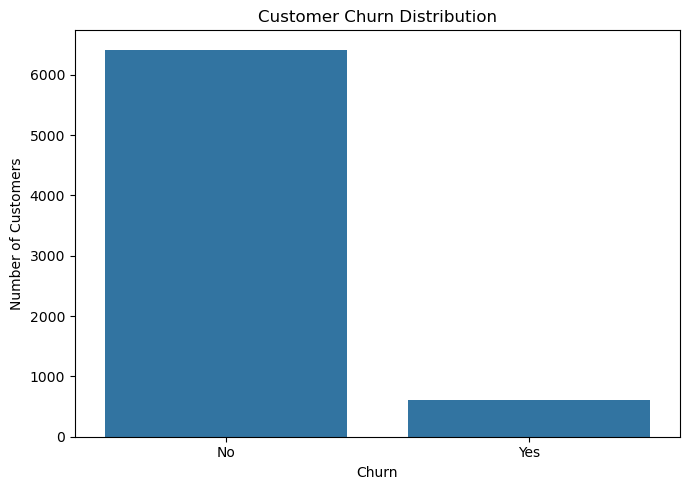

In [1131]:
# Churn Distribution

print("Churn Distribution:")
display(df["Churn"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()

import os
os.makedirs("../Visualizations", exist_ok=True)

plt.savefig("../Visualizations/churn_distribution.png")
plt.show()

Churn Percentage:


Churn
No     91.42
Yes     8.58
Name: proportion, dtype: float64

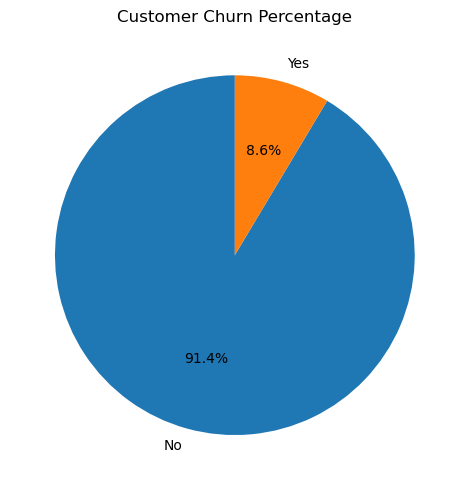

In [1132]:
# Churn Percentage

churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("Churn Percentage:")
display(churn_percentage.round(2))

plt.figure(figsize=(7, 5))
plt.pie(
    churn_percentage.values,
    labels=churn_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Customer Churn Percentage")
plt.tight_layout()

plt.savefig("../Visualizations/churn_percentage.png")
plt.show()

Churn by Contract:


Churn,No,Yes
Contract,,
Month-to-month,3395,467
One year,1390,83
Two year,1631,52


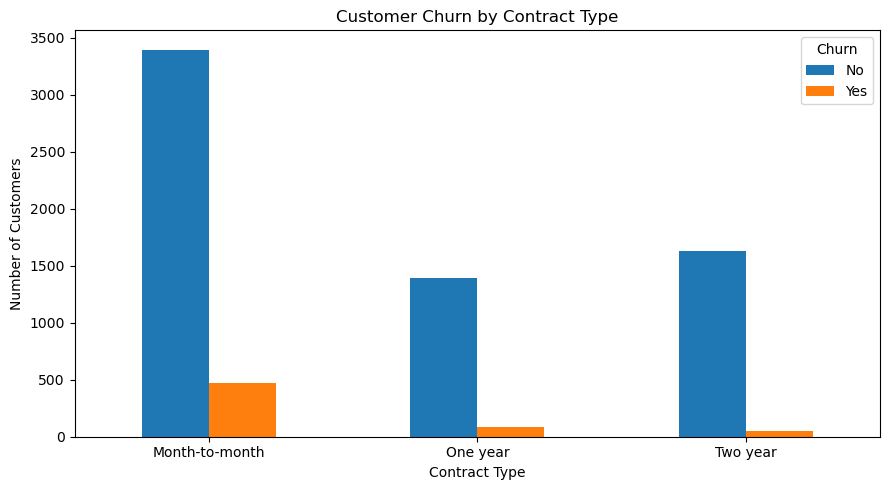

In [1133]:
# Churn by Contract Type

contract_churn = pd.crosstab(df["Contract"], df["Churn"])

print("Churn by Contract:")
display(contract_churn)

contract_churn.plot(kind="bar", figsize=(9, 5))
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualizations/churn_by_contract.png")
plt.show()

Churn by Internet Service:


Churn,No,Yes
InternetService,,
DSL,2267,156
Fiber optic,2688,356
No,1461,90


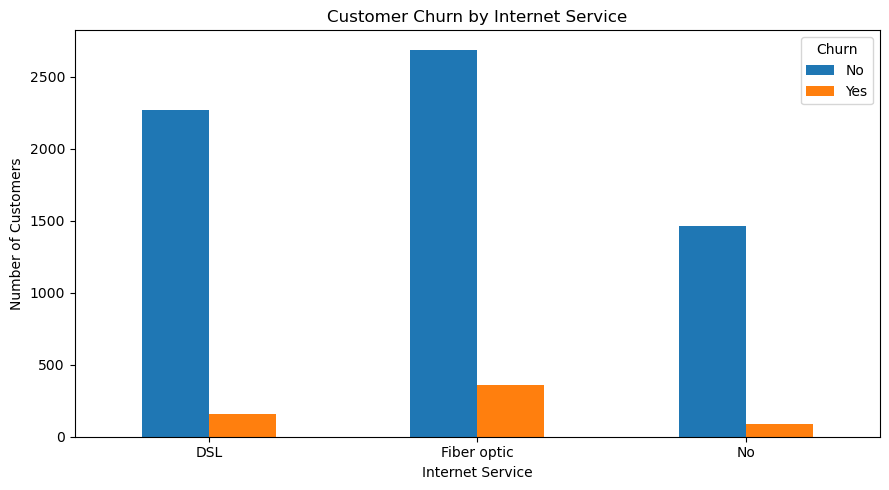

In [1134]:
# Churn by Internet Service

internet_churn = pd.crosstab(df["InternetService"], df["Churn"])

print("Churn by Internet Service:")
display(internet_churn)

internet_churn.plot(kind="bar", figsize=(9, 5))
plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Visualizations/churn_by_internet_service.png")
plt.show()

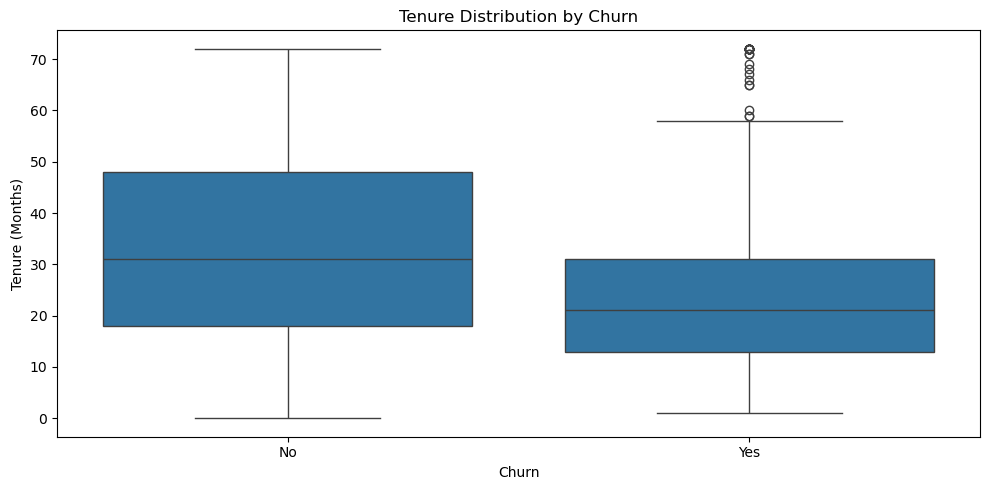

In [1135]:
# Churn by Tenure

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()

plt.savefig("../Visualizations/churn_by_tenure.png")
plt.show()

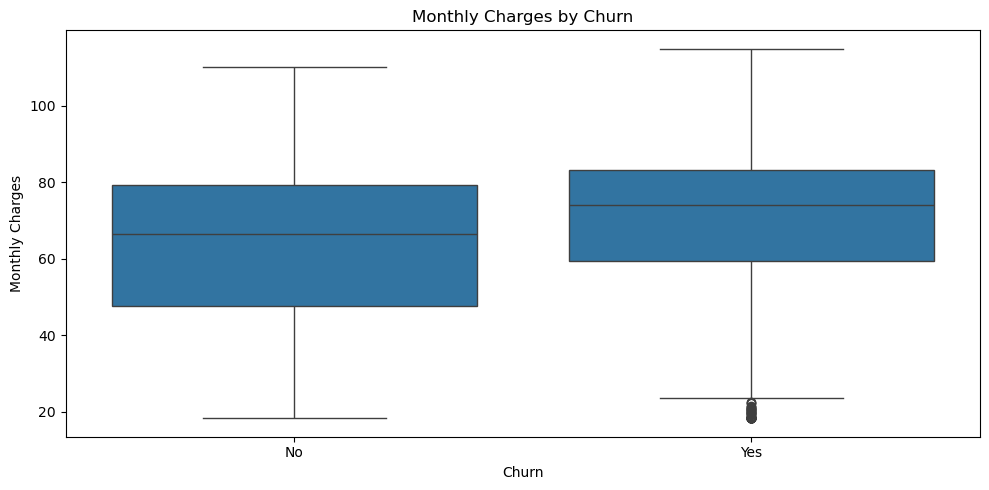

In [1136]:
# Monthly Charges vs Churn

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()

plt.savefig("../Visualizations/monthly_charges_vs_churn.png")
plt.show()

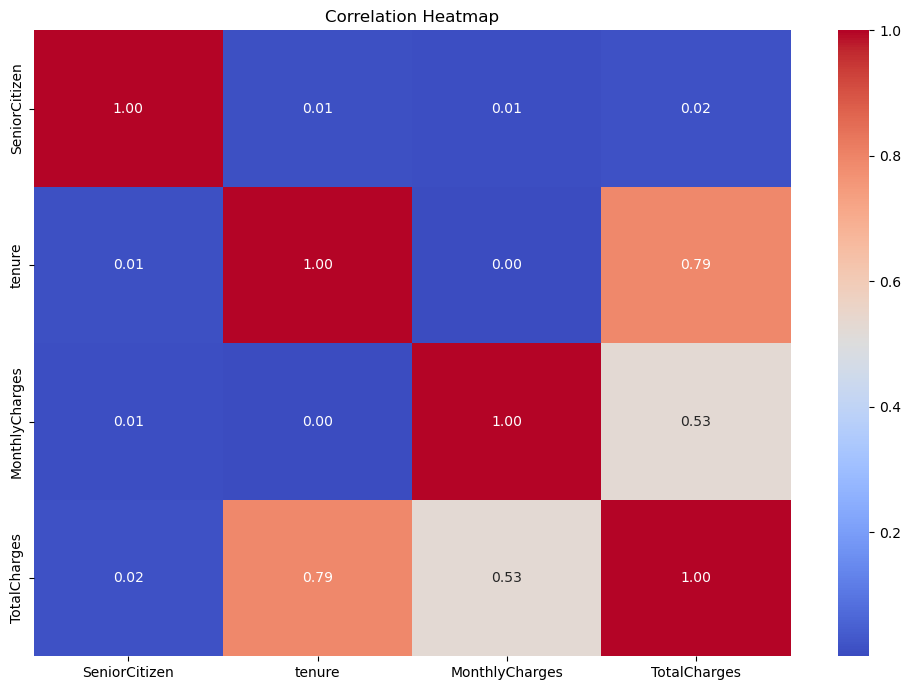

In [1137]:
# Correlation Heatmap

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig("../Visualizations/correlation_heatmap.png")
plt.show()

In [1138]:
# Basic EDA Insights

print("===== EDA INSIGHTS =====")

print("\n1. Contract-wise churn:")
display(pd.crosstab(df["Contract"], df["Churn"], normalize="index").round(3) * 100)

print("\n2. Internet service-wise churn:")
display(pd.crosstab(df["InternetService"], df["Churn"], normalize="index").round(3) * 100)

print("\n3. Average tenure by churn:")
display(df.groupby("Churn")["tenure"].mean().round(2))

print("\n4. Average monthly charges by churn:")
display(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

===== EDA INSIGHTS =====

1. Contract-wise churn:


Churn,No,Yes
Contract,,
Month-to-month,87.9,12.1
One year,94.4,5.6
Two year,96.9,3.1



2. Internet service-wise churn:


Churn,No,Yes
InternetService,,
DSL,93.6,6.4
Fiber optic,88.3,11.7
No,94.2,5.8



3. Average tenure by churn:


Churn
No     34.31
Yes    24.07
Name: tenure, dtype: float64


4. Average monthly charges by churn:


Churn
No     60.73
Yes    67.67
Name: MonthlyCharges, dtype: float64

# Data Mining - Customer Segmentation using K-Means

In [1139]:
# Select features for customer segmentation

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

segmentation_data = df[[
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]].copy()

print("Segmentation data shape:", segmentation_data.shape)
display(segmentation_data.head())

Segmentation data shape: (7018, 3)


,tenure,MonthlyCharges,TotalCharges
0,49,65.12,3185.16
1,11,84.56,894.51
2,53,90.66,4863.12
3,26,65.00,1697.23
4,22,18.25,392.47


In [1140]:
# Scale the segmentation features

scaler_kmeans = StandardScaler()

scaled_data = scaler_kmeans.fit_transform(segmentation_data)

print("Feature scaling completed!")
print("Scaled data shape:", scaled_data.shape)

Feature scaling completed!
Scaled data shape: (7018, 3)


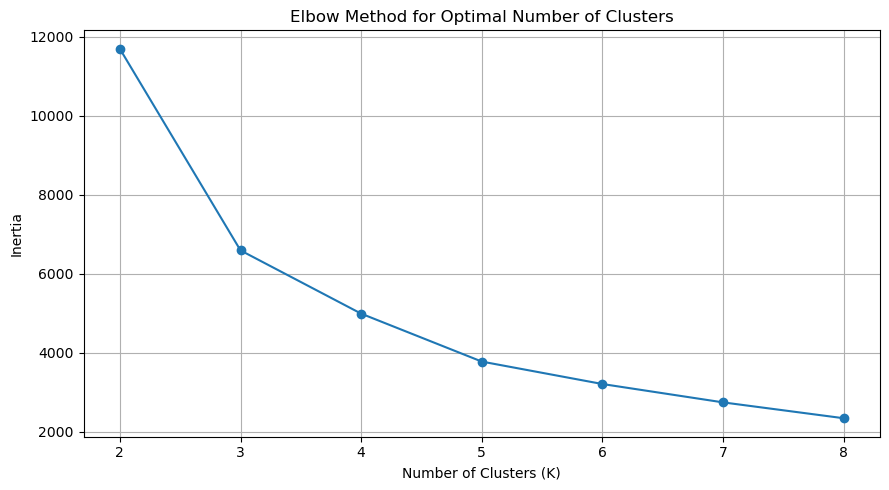

In [1141]:
# Elbow Method

inertia = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(scaled_data)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(range(2, 9), inertia, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.grid(True)
plt.tight_layout()

plt.savefig("../Visualizations/kmeans_elbow.png")
plt.show()

In [1142]:
# Apply K-Means Clustering

kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["CustomerSegment"] = kmeans_model.fit_predict(scaled_data)

print("K-Means clustering completed!")

print("\nCustomer count in each segment:")
display(df["CustomerSegment"].value_counts().sort_index())

K-Means clustering completed!

Customer count in each segment:


CustomerSegment
0    3481
1    1663
2    1874
Name: count, dtype: int64

In [1143]:
# Analyze Customer Segments

segment_summary = df.groupby("CustomerSegment")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].mean().round(2)

print("Customer Segment Summary:")
display(segment_summary)

Customer Segment Summary:


,tenure,MonthlyCharges,TotalCharges
CustomerSegment,,,
0,21.27,72.65,1531.60
1,32.75,23.18,759.53
2,56.63,74.15,4165.40


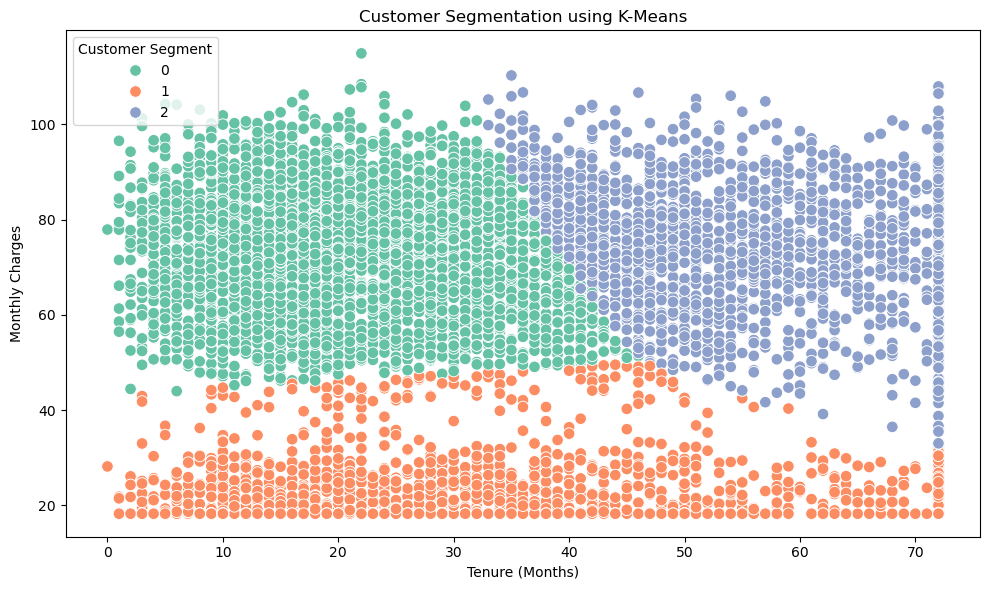

In [1144]:
# Visualize Customer Segments

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="tenure",
    y="MonthlyCharges",
    hue="CustomerSegment",
    palette="Set2",
    s=70
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.legend(title="Customer Segment")
plt.tight_layout()

plt.savefig("../Visualizations/customer_segmentation_kmeans.png")
plt.show()

Churn Percentage by Customer Segment:


Churn,No,Yes
CustomerSegment,,
0,87.93,12.07
1,94.17,5.83
2,95.46,4.54


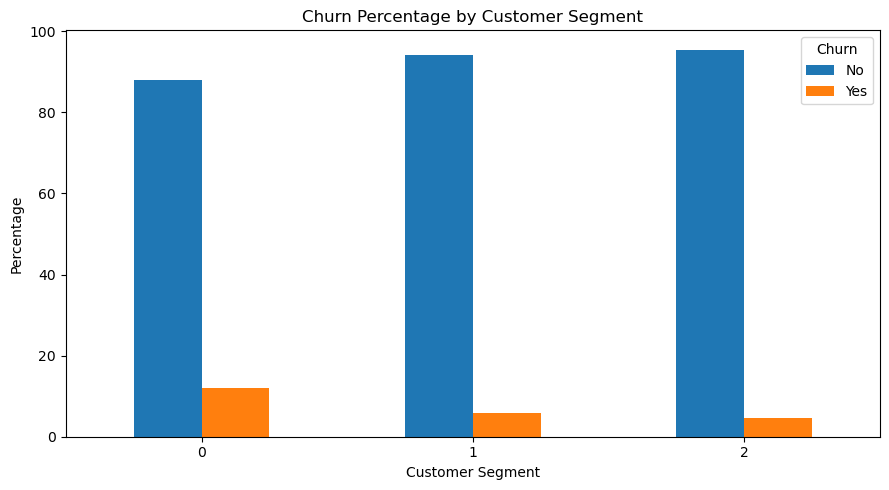

In [1145]:
# Analyze Churn by Customer Segment

segment_churn = pd.crosstab(
    df["CustomerSegment"],
    df["Churn"],
    normalize="index"
) * 100

segment_churn = segment_churn.round(2)

print("Churn Percentage by Customer Segment:")
display(segment_churn)

segment_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Percentage by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()

plt.savefig("../Visualizations/churn_by_customer_segment.png")
plt.show()

In [1146]:
# Save Dataset with Customer Segments

segmented_path = "../Outputs/customer_segmented_data.csv"

df.to_csv(segmented_path, index=False)

print("Segmented dataset saved successfully!")
print("Location:", segmented_path)

Segmented dataset saved successfully!
Location: ../Outputs/customer_segmented_data.csv


# Feature Engineering and ML Data Preparation

In [1147]:
# Convert Churn into numerical target

df["Churn_Encoded"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Target encoding completed!")
display(df[["Churn", "Churn_Encoded"]].head())

Target encoding completed!


,Churn,Churn_Encoded
0,No,0
1,No,0
2,No,0
3,No,0
4,No,0


In [1148]:
# Convert Churn into numerical target

df["Churn_Encoded"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Target encoding completed!")
display(df[["Churn", "Churn_Encoded"]].head())

Target encoding completed!


,Churn,Churn_Encoded
0,No,0
1,No,0
2,No,0
3,No,0
4,No,0


In [1149]:
# Separate input features and target

X = df.drop(
    columns=["Churn", "Churn_Encoded", "CustomerSegment"],
    errors="ignore"
)

y = df["Churn_Encoded"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (7018, 19)
Target shape: (7018,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [1150]:
# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [1151]:
# Split dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (5614, 19)
Testing data: (1404, 19)

Training target distribution:
Churn_Encoded
0    5132
1     482
Name: count, dtype: int64

Testing target distribution:
Churn_Encoded
0    1284
1     120
Name: count, dtype: int64


In [1152]:
# Create preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [1153]:
# Fit preprocessing only on training data

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Preprocessing completed!
Processed training shape: (5614, 45)
Processed testing shape: (1404, 45)


In [1154]:
# Get processed feature names

feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))

print("\nFirst 20 processed features:")
print(feature_names[:20])

Number of processed features: 45

First 20 processed features:
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'cat__gender_Female' 'cat__gender_Male'
 'cat__Partner_No' 'cat__Partner_Yes' 'cat__Dependents_No'
 'cat__Dependents_Yes' 'cat__PhoneService_No' 'cat__PhoneService_Yes'
 'cat__MultipleLines_No' 'cat__MultipleLines_No phone service'
 'cat__MultipleLines_Yes' 'cat__InternetService_DSL'
 'cat__InternetService_Fiber optic' 'cat__InternetService_No'
 'cat__OnlineSecurity_No' 'cat__OnlineSecurity_No internet service']


# Machine Learning Model Training

In [1155]:
# Import Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

print("All ML models imported successfully!")

All ML models imported successfully!


In [1156]:
# Create ML Models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=8
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    )
}

print("Models created successfully!")

Models created successfully!


In [1157]:
# Train all models

trained_models = {}

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    trained_models[name] = model
    print(f"{name} trained successfully!")

print("\nAll models trained successfully!")

Logistic Regression trained successfully!


Decision Tree trained successfully!
Random Forest trained successfully!
KNN trained successfully!


c:\Users\hp\anaconda3\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM trained successfully!

All models trained successfully!


In [1158]:
# Generate predictions from all models

predictions = {}

for name, model in trained_models.items():
    predictions[name] = model.predict(X_test_processed)

print("Predictions generated successfully!")

Predictions generated successfully!


# Model Evaluation and Comparison

In [1159]:
# Evaluate all trained models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_processed)
    
    # Probability needed for ROC-AUC
    y_prob = model.predict_proba(X_test_processed)[:, 1]
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

# Round values for display
results_display = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_display[metric_columns] = results_display[metric_columns].round(4)

display(results_display)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9117,0.1667,0.0083,0.0159,0.7440
1,Decision Tree,0.8974,0.1000,0.0250,0.0400,0.6515
2,Random Forest,0.9131,0.0000,0.0000,0.0000,0.6810
3,KNN,0.9017,0.1538,0.0333,0.0548,0.5745
4,SVM,0.9145,0.0000,0.0000,0.0000,0.6146


In [1160]:
# Select the best model based on F1 Score

best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:", round(
    results_df.loc[results_df["F1 Score"].idxmax(), "F1 Score"],
    4
))

Best Model: KNN
Best F1 Score: 0.0548


<Figure size 1000x600 with 0 Axes>

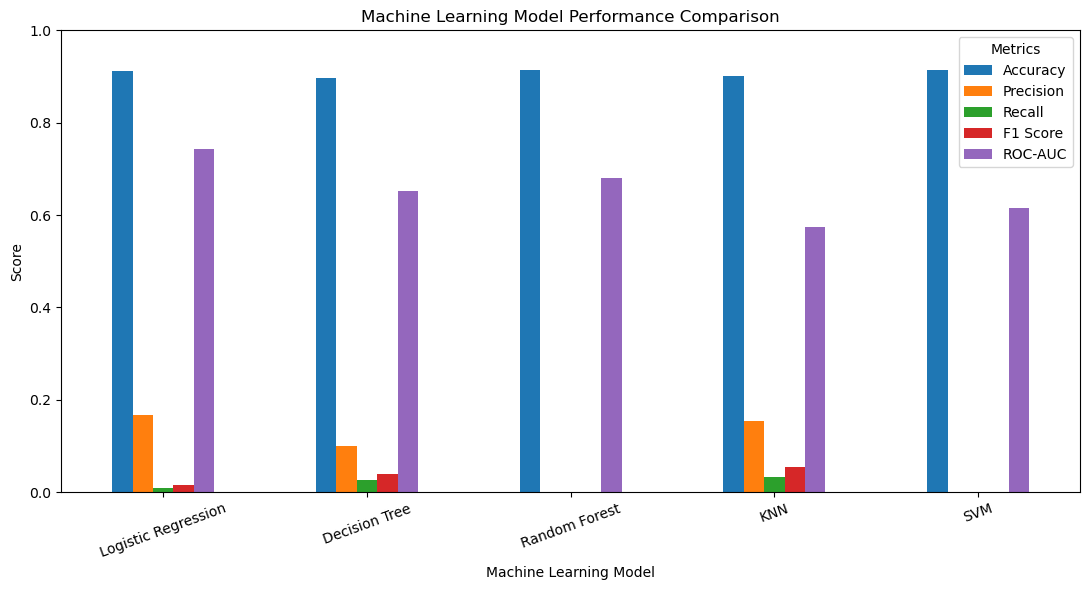

In [1161]:
# Compare Model Performance

plt.figure(figsize=(10, 6))

results_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
]

results_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(title="Metrics")
plt.tight_layout()

plt.savefig("../Visualizations/model_performance_comparison.png")
plt.show()

In [1162]:
# Save model comparison results

results_df.to_csv(
    "../Outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")
print("File: Outputs/model_comparison.csv")

Model comparison saved successfully!
File: Outputs/model_comparison.csv


# Confusion Matrix Analysis

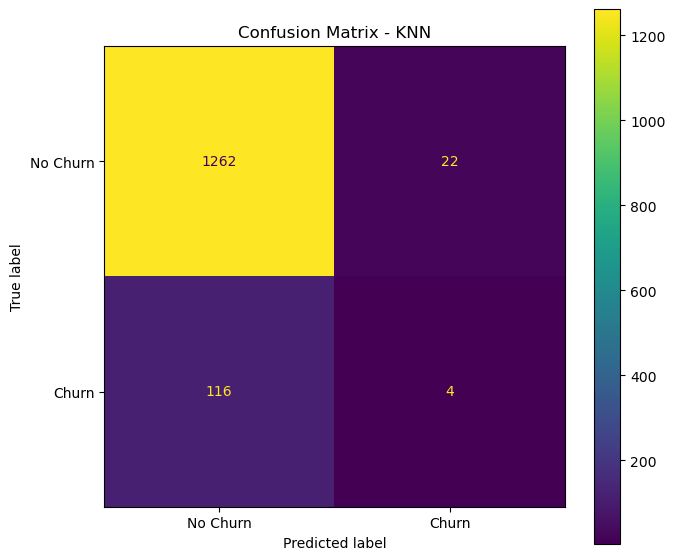

In [1163]:
# Confusion Matrix for Best Model

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_predictions = best_model.predict(X_test_processed)

cm = confusion_matrix(y_test, best_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()

plt.savefig(
    "../Visualizations/best_model_confusion_matrix.png"
)

plt.show()

In [1164]:
# Detailed classification report

from sklearn.metrics import classification_report

print(f"Classification Report - {best_model_name}\n")

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

Classification Report - KNN

              precision    recall  f1-score   support

    No Churn       0.92      0.98      0.95      1284
       Churn       0.15      0.03      0.05       120

    accuracy                           0.90      1404
   macro avg       0.53      0.51      0.50      1404
weighted avg       0.85      0.90      0.87      1404



# Save Final Models for Deployment

In [1165]:
# Save the best churn prediction model

import joblib
import os

os.makedirs("../Models", exist_ok=True)

joblib.dump(
    best_model,
    "../Models/best_churn_model.pkl"
)

print("Best churn model saved successfully!")
print("Model:", best_model_name)
print("File: Models/best_churn_model.pkl")

Best churn model saved successfully!
Model: KNN
File: Models/best_churn_model.pkl


In [1166]:
# Save preprocessing pipeline

joblib.dump(
    preprocessor,
    "../Models/churn_preprocessor.pkl"
)

print("Churn preprocessor saved successfully!")

Churn preprocessor saved successfully!


In [1167]:
# Save K-Means model and scaler

joblib.dump(
    kmeans_model,
    "../Models/customer_segmentation_kmeans.pkl"
)

joblib.dump(
    scaler_kmeans,
    "../Models/kmeans_scaler.pkl"
)

print("K-Means model saved successfully!")
print("K-Means scaler saved successfully!")

K-Means model saved successfully!
K-Means scaler saved successfully!


In [1168]:
# Save best model information

best_row = results_df[
    results_df["Model"] == best_model_name
].iloc[0]

model_info = {
    "Best Model": best_model_name,
    "Accuracy": round(float(best_row["Accuracy"]), 4),
    "Precision": round(float(best_row["Precision"]), 4),
    "Recall": round(float(best_row["Recall"]), 4),
    "F1 Score": round(float(best_row["F1 Score"]), 4),
    "ROC-AUC": round(float(best_row["ROC-AUC"]), 4)
}

import json

with open("../Models/model_info.json", "w") as f:
    json.dump(model_info, f, indent=4)

print("Model information saved successfully!")
print(model_info)

Model information saved successfully!
{'Best Model': 'KNN', 'Accuracy': 0.9017, 'Precision': 0.1538, 'Recall': 0.0333, 'F1 Score': 0.0548, 'ROC-AUC': 0.5745}


In [1169]:
# Save best model information

best_row = results_df[
    results_df["Model"] == best_model_name
].iloc[0]

model_info = {
    "Best Model": best_model_name,
    "Accuracy": round(float(best_row["Accuracy"]), 4),
    "Precision": round(float(best_row["Precision"]), 4),
    "Recall": round(float(best_row["Recall"]), 4),
    "F1 Score": round(float(best_row["F1 Score"]), 4),
    "ROC-AUC": round(float(best_row["ROC-AUC"]), 4)
}

import json

with open("../Models/model_info.json", "w") as f:
    json.dump(model_info, f, indent=4)

print("Model information saved successfully!")
print(model_info)

Model information saved successfully!
{'Best Model': 'KNN', 'Accuracy': 0.9017, 'Precision': 0.1538, 'Recall': 0.0333, 'F1 Score': 0.0548, 'ROC-AUC': 0.5745}
